<a href="https://colab.research.google.com/github/pranav15082007-tech/numpy-dtype-benchmark-lab/blob/main/numpy_dtype_optimizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import time
import matplotlib.pyplot as plt

In [ ]:
rng = np.random.default_rng(2024)
n = 1_000_000
int_names = np.array(['age','rating','brightness','customer_id'])
ints = rng.integers([18,1,0,1], [91,6,256,5_000_001],size=(n, 4))
float_names = np.array(['price','temperature'])
floats = np.column_stack((np.round(rng.uniform(10,5000,n),2),
                          np.round(rng.normal(30,5,n),1)))
print(ints.shape, ints.dtype, ints.nbytes/1e6,"MB")
print(floats.shape, floats.dtype, floats.nbytes/1e6,"MB")
total_before = (ints.nbytes + floats.nbytes)/1e6
print("TOTAL:",total_before,"MB")

(1000000, 4) int64 32.0 MB
(1000000, 2) float64 16.0 MB
TOTAL: 48.0 MB


In [ ]:
col_min = ints.min(axis=0)
col_max = ints.max(axis=0)
print(col_min)
print(col_max)

[18  1  0  4]
[     90       5     255 5000000]


In [ ]:
type_names = np.array(['uint8','int8','uint16','int16','uint32','int32','int64'])
lows  = np.array([0,-128,0,-32768,0,-2147483648,-9223372036854775808])
highs = np.array([255,127,65535,32767,4294967295,2147483647,9223372036854775807])
sizes = np.array([1,1,2,2,4,4,8])

In [ ]:
fits = (col_min[:,None]>=lows)&(col_max[:,None]<=highs)
print(fits)
best_idx = fits.argmax(axis=1)
best_int_types = type_names[best_idx]
print(best_int_types)

[[ True  True  True  True  True  True  True]
 [ True  True  True  True  True  True  True]
 [ True False  True  True  True  True  True]
 [False False False False  True  True  True]]
['uint8' 'uint8' 'uint8' 'uint32']


In [ ]:
error = np.abs(floats-floats.astype('float32')).max(axis=0)
safe = error<0.01
best_float_types = np.where(safe,'float32','float64')
print(error)
print(best_float_types)

[2.34375000e-04 1.52587891e-06]
['float32' 'float32']


In [ ]:
small_ints =[]
for i in range(4):
    small_ints.append(ints[:,i].astype(best_int_types[i]))

small_floats =[]
for j in range(2):
    small_floats.append(floats[:,j].astype(best_float_types[j]))

In [ ]:
all_names = np.concatenate((int_names,float_names))
before_mb = np.full(6,8*n/1e6)
after_mb = np.concatenate((sizes[best_idx], np.where(safe,4,8)))*n /1e6
saved = (1-after_mb/before_mb)*100
print(all_names)
print(before_mb)
print(after_mb)
print(saved.round(1))
print("TOTAL:",before_mb.sum(),"->",after_mb.sum(),"MB")
print("Saved overall:",round((1-after_mb.sum()/before_mb.sum())*100, 1),"%")

actual = sum(a.nbytes for a in small_ints + small_floats)/1e6
print("Actual MB:",actual)

['age' 'rating' 'brightness' 'customer_id' 'price' 'temperature']
[8. 8. 8. 8. 8. 8.]
[1. 1. 1. 4. 4. 4.]
[87.5 87.5 87.5 50.  50.  50. ]
TOTAL: 48.0 -> 15.0 MB
Saved overall: 68.8 %
Actual MB: 15.0


In [ ]:
for i in range(4):
    print(int_names[i], np.array_equal(ints[:,i], small_ints[i]))
for j in range(2):
    print(float_names[j], np.abs(floats[:,j]-small_floats[j]).max())

age True
rating True
brightness True
customer_id True
price 0.00023437500021827873
temperature 1.5258789076710855e-06


In [ ]:
wrong = ints[:,2].astype(np.int8)
changed = np.count_nonzero(wrong != ints[:,2])
print("Values corrupted:",changed,"out of",n)
print("Brightness values above 127:",np.sum(ints[:,2]>127))
wrong2 = ints[:,3].astype(np.int16)
print("customer_id corrupted:", np.count_nonzero(wrong2 != ints[:,3])/n*100,"%")

Values corrupted: 500017 out of 1000000
Brightness values above 127: 500017
customer_id corrupted: 99.3554 %


In [ ]:
big = [ints[:,i].copy() for i in range(4)]+[floats[:, j].copy() for j in range(2)]
small = small_ints+small_floats

def stopwatch(arrays):
    start = time.time()
    for k in range(50):
        for a in arrays:
            a.sum()
    return (time.time()-start)/50*1000

print("Original (ms):",round(stopwatch(big), 2))
print("Optimized (ms):",round(stopwatch(small), 2))

Original (ms): 4.37
Optimized (ms): 2.48


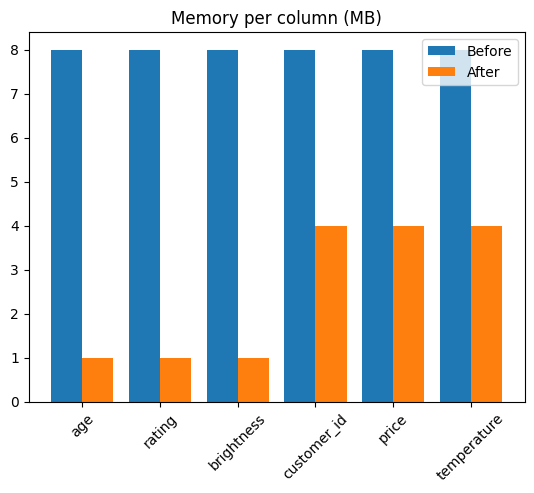

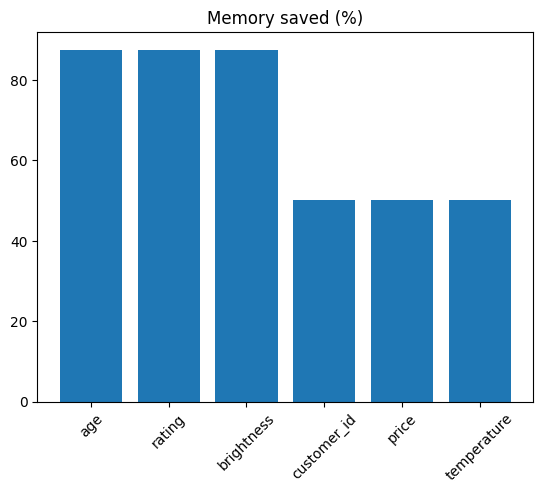

In [ ]:
x = np.arange(6)
plt.bar(x-0.2, before_mb,width=0.4,label='Before')
plt.bar(x+0.2, after_mb,width=0.4,label='After')
plt.xticks(x, all_names,rotation=45)
plt.title('Memory per column (MB)')
plt.legend()
plt.show()

plt.bar(all_names,saved)
plt.title('Memory saved (%)')
plt.xticks(rotation=45)
plt.show()

## Conclusions

**Memory savings**
NumPy stores whole numbers as int64 and decimals as float64 by default, which wastes memory when the values are small. By checking each column's minimum and maximum, I cut the dataset from 48 MB to 15 MB, a saving of 68.8%.

| Column | Before | After | Reason |
|---|---|---|---|
| age (18 to 90) | int64 (8 bytes) | uint8 (1 byte) | fits within 0 to 255 |
| rating (1 to 5) | int64 (8 bytes) | uint8 (1 byte) | fits within 0 to 255 |
| brightness (0 to 255) | int64 (8 bytes) | uint8 (1 byte) | exactly fits 0 to 255 |
| customer_id (up to 5,000,000) | int64 (8 bytes) | uint32 (4 bytes) | too big for 1 or 2 bytes |
| price | float64 (8 bytes) | float32 (4 bytes) | rounding error under 0.01 |
| temperature | float64 (8 bytes) | float32 (4 bytes) | rounding error under 0.01 |

**No data was lost**
After conversion, I compared every integer column with the original using `np.array_equal`, and all of them matched exactly. For the float columns, the largest difference was tiny (about 0.0002 for price and 0.000002 for temperature).

**Choosing the wrong type is dangerous**
- Storing brightness as int8 corrupted 500,017 values (about 50%). int8 stops at 127, and brightness goes up to 255. The corrupted count exactly matched the number of values above 127.
- Storing customer_id as int16 corrupted about 99% of the values, because int16 stops at 32,767.
- NumPy gave **no error or warning** in either case. The numbers just wrapped around silently.
- **Lesson:** always check the minimum and maximum before downcasting.

**Speed**
Summing all six columns took about 4.37 ms with the original types (int64/float64) and about 2.48 ms with the optimized types, so the optimized data was roughly 1.8x faster (about 43% less time). Smaller types mean less data for the CPU to read from memory, which can make operations faster. The exact numbers vary by machine and between runs, so the memory savings are the more reliable result.

**Key takeaway**
Smaller data types mainly save memory. They help when working with large datasets, but they are only safe when the data fits inside the type's range.